In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_panel = pd.read_csv('../data/processed/nigeria_panel_features_2018_2023.csv')
df_panel['log_viirs'] = np.log1p(df_panel['viirs_mean_radiance'])

print(f"Panel shape: {df_panel.shape}")
print(f"Years covered: {sorted(df_panel['year'].unique())}")
print(f"Unique states: {df_panel['state_name'].nunique()}")

# Plot national annual median trajectory
annual_trend = df_panel.groupby('year')[['viirs_mean_radiance', 'modis_mean_ndvi']].mean()
print("\nNational Annual Averages across all 37 States:")
print(annual_trend.round(4))

Panel shape: (222, 5)
Years covered: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
Unique states: 37

National Annual Averages across all 37 States:
      viirs_mean_radiance  modis_mean_ndvi
year                                      
2018               0.7800           0.4494
2019               0.6600           0.4562
2020               0.7265           0.4516
2021               0.6594           0.4452
2022               0.6925           0.4231
2023               0.6695           0.4593


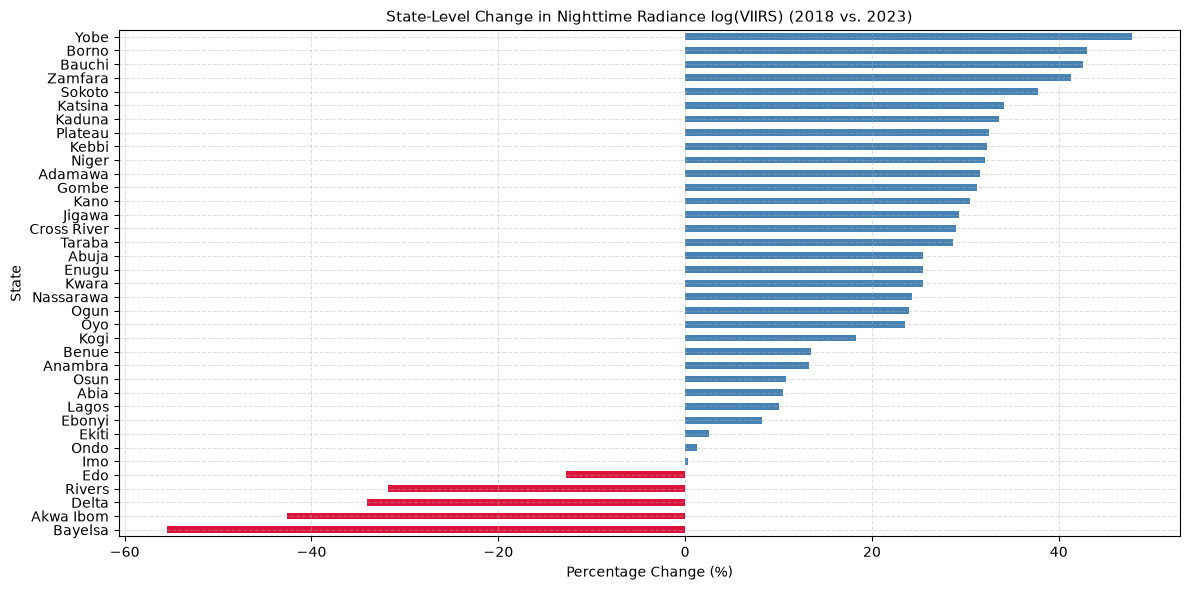

✓ Saved growth trajectory plot to docs/panel_radiance_growth.png


In [2]:
# Pivot to calculate 5-year growth in night lights
pvt = df_panel.pivot(index='state_name', columns='year', values='log_viirs')
pvt['growth_pct'] = ((pvt[2023] - pvt[2018]) / pvt[2018]) * 100

plt.figure(figsize=(12, 6))
top_growth = pvt['growth_pct'].sort_values()
top_growth.plot(kind='barh', color=np.where(top_growth > 0, 'steelblue', 'crimson'))

plt.title("State-Level Change in Nighttime Radiance log(VIIRS) (2018 vs. 2023)", fontsize=11)
plt.xlabel("Percentage Change (%)")
plt.ylabel("State")
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('../docs/panel_radiance_growth.png', dpi=300)
plt.show()

print("✓ Saved growth trajectory plot to docs/panel_radiance_growth.png")

In [3]:
from linearmodels.panel import PanelOLS

# Set MultiIndex (Entity, Time)
df_panel_indexed = df_panel.set_index(['state_name', 'year'])

# 1. Pooled OLS baseline
pooled = PanelOLS(df_panel_indexed['log_viirs'], df_panel_indexed[['modis_mean_ndvi']])
res_pooled = pooled.fit(cov_type='clustered', cluster_entity=True)

# 2. Entity Fixed Effects (Within-estimator controlling for state-specific unobservables)
fe_model = PanelOLS(df_panel_indexed['log_viirs'], df_panel_indexed[['modis_mean_ndvi']], entity_effects=True)
res_fe = fe_model.fit(cov_type='clustered', cluster_entity=True)

print("=== Panel Fixed Effects Regression Output ===")
print(res_fe.summary)

=== Panel Fixed Effects Regression Output ===
                          PanelOLS Estimation Summary                           
Dep. Variable:              log_viirs   R-squared:                        0.0357
Estimator:                   PanelOLS   R-squared (Between):             -1.9839
No. Observations:                 222   R-squared (Within):               0.0357
Date:                Mon, Oct 19 2026   R-squared (Overall):             -1.9377
Time:                        21:22:02   Log-likelihood                    231.35
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      6.8097
Entities:                          37   P-value                           0.0098
Avg Obs:                       6.0000   Distribution:                   F(1,184)
Min Obs:                       6.0000                                           
Max Obs:                       6.0000   F-statistic (robust):  